$\text{\large{Section 1: Data Analysis}}$

We take a look at the kinds of data for house establishments and whether or not a bank should be put in these cities for offering loans. Here is a description on the specific analysis done.

1) Population vs median home value
   - This plot explores whether ZIP codes with larger populations also have higher median home values. We use this to identify areas where more people create higher housing demand, which may be attractive for banks due to growth potential and lending opportunities.

2) Median House Price per Sqr Ft over time
   - Tracking the median price per square foot over time by metro gives a clear view of the real estate market's appreciation, volatility, and comparative cost. This informs about long-term investment potential and hotspots of value growth.

3) Hotness metric score vs days on the market
   - By correlating the Realtor.com hotness score (a measure of demand) with the number of days properties spend on market, we measure which ZIPs are most competitive. Fast-moving, in-demand markets signal robust lending environments.

4) Market hotness over time
   - Charting the average hotness score over time captures how quickly and persistently properties are being absorbed in each metro. Rising scores suggest an increasingly dynamic and competitive market—attractive for financial services expansion.

5) Median Listing Pricing over time
   - Examining the trajectory of median listing prices by month helps assess whether home values are stable, rising, or volatile, providing a window into the market’s health and the risks for new loan originations.

6) Population vs median housing income by zip level
   - This plot visualizes how income levels vary with population across ZIPs. Areas with both large populations and high incomes may offer the richest opportunities for banks to target well-qualified borrowers.

7) Population Density vs Median Home Value by metro
   - By studying the relationship between how densely populated a ZIP is and its median home value, we see which neighborhoods are most "packed and pricey", indicating potential for both high demand and high lending volumes.

8) Affordability ratio by metro
   - The affordability ratio (median home value / median household income) helps identify markets where home prices are high relative to incomes—potentially indicating buyer stress, speculative bubbles, or, conversely, wealthy neighborhoods.

9) Population vs Median Gross Rent
   - Comparing ZIP-level population with gross rent uncovers whether larger or denser communities face greater rental costs, revealing where rental markets may be under pressure and more demand for lending products could arise.

10) Geospatial Data

   - Mapping ZIP codes by population density and home value offers an intuitive, spatial overview of where people live and how much they pay for housing, highlighting geographic pockets of opportunity or risk for branch and lending strategies.


Strongly emphasized on the population aspect of things, to see how this greatly influences the house economy in these metros.

In [5]:
#Import needed libaries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:

# Load needed data from the CSV cleaned
census = pd.read_csv('data/processed/census_zcta.csv')
realtor = pd.read_csv('data/processed/realtor_zip_monthly.csv')


Population vs median home value

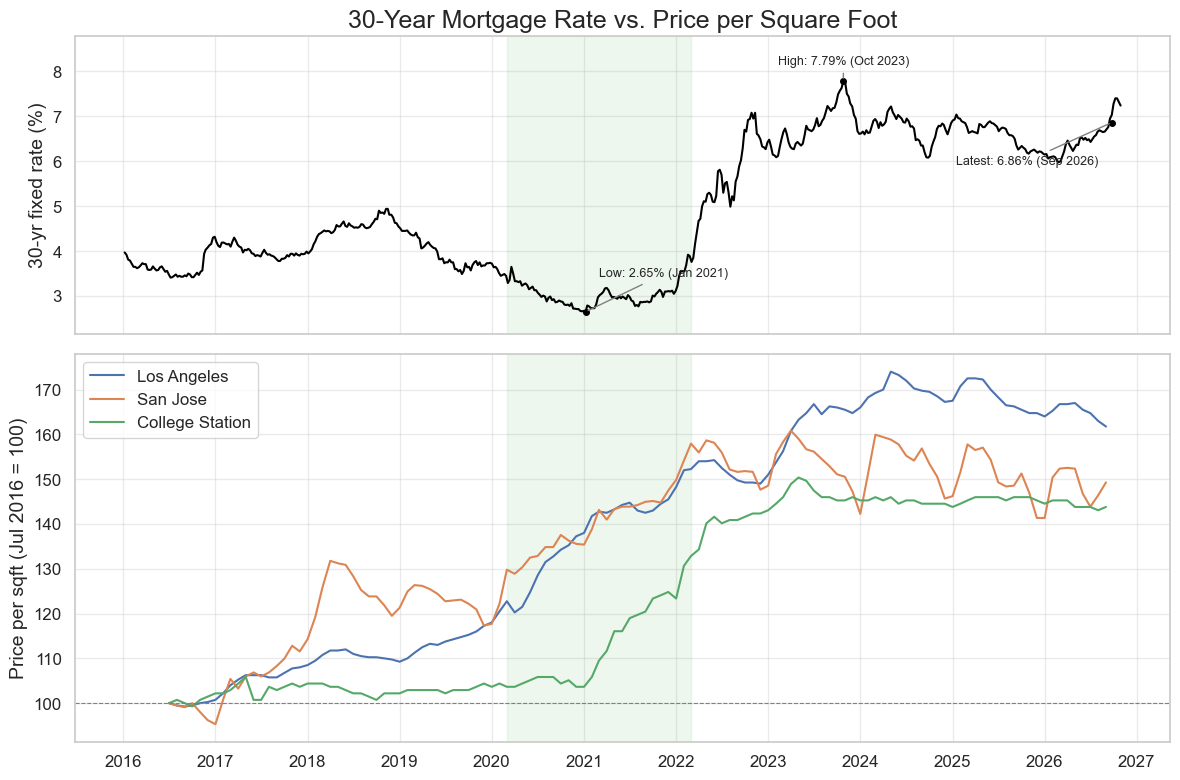

In [ ]:
#30-year mortgage rate vs. price per sqft 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fred = pd.read_csv('data/processed/fred_observations.csv', parse_dates=['date'])
rate = fred[(fred['series_id'] == 'MORTGAGE30US') & (fred['date'] >= '2016-01-01')].set_index('date')['value']

metro = pd.read_csv('data/processed/realtor_metro_monthly.csv', parse_dates=['date'])
ppsf = (metro.pivot(index='date', columns='metro_key', values='median_listing_price_per_square_foot')
             .loc['2016-07-01':])
ppsf_index = ppsf / ppsf.iloc[0] * 100            # July 2016 = 100, so growth rates are comparable

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={'height_ratios': [1, 1.3]})

# Top: mortgage rate, with the low, the high and the latest value labeled from the data
ax1.plot(rate.index, rate, color='black')
low = rate.loc['2020':'2022'].idxmin()      # pandemic-era low
high = rate.loc['2022':'2024'].idxmax()     # post-tightening peak
latest = rate.loc[:'2026-09-30'].index[-1]
rate.loc[latest] = rate.loc['2026-09'].mean()
labels = [(low, 'Low', (10, 25), 'left'), (high, 'High', (0, 12), 'center'),
          (latest, 'Latest', (-10, -30), 'right')]
for when, label, offset, ha in labels:
    ax1.annotate(f'{label}: {rate[when]:.2f}% ({when:%b %Y})', xy=(when, rate[when]),
                 xytext=offset, textcoords='offset points', ha=ha, fontsize=9,
                 arrowprops=dict(arrowstyle='-', color='gray'))
    ax1.plot(when, rate[when], 'o', color='black', markersize=4)
ax1.set_ylim(rate.min() - 0.5, rate.max() + 1.0)
ax1.set_ylabel('30-yr fixed rate (%)')
ax1.set_title('30-Year Mortgage Rate vs. Price per Square Foot')
ax1.grid(True, alpha=0.4)

# Bottom: price per sqft by metro, indexed
names = {'los_angeles': 'Los Angeles', 'san_jose': 'San Jose', 'college_station': 'College Station'}
for key, name in names.items():
    ax2.plot(ppsf_index.index, ppsf_index[key], label=name)
ax2.axhline(100, color='gray', linewidth=0.8, linestyle='--')
ax2.set_ylabel('Price per sqft (Jul 2016 = 100)')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.4)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Shade the low-rate period on both panels
for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2022-03-01'), color='tab:green', alpha=0.08)

plt.tight_layout()
plt.savefig('mortgage_vs_ppsf.png', dpi=200)
plt.show()

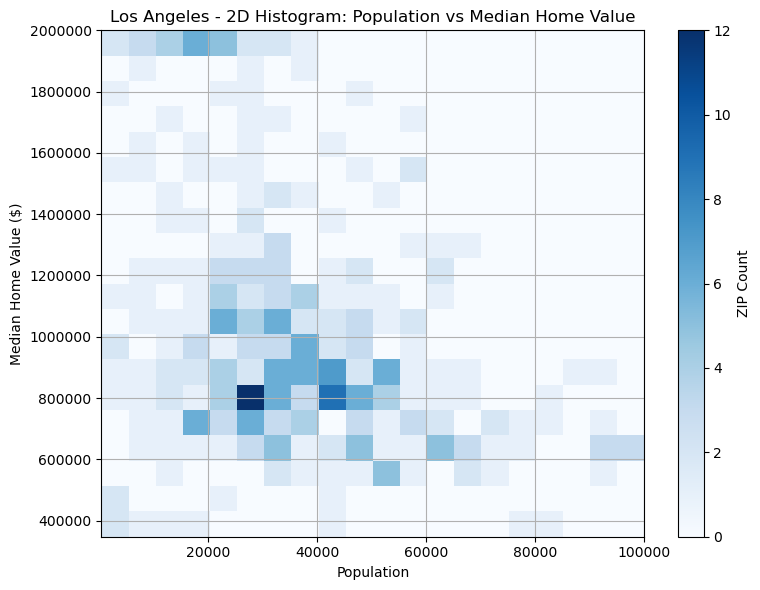

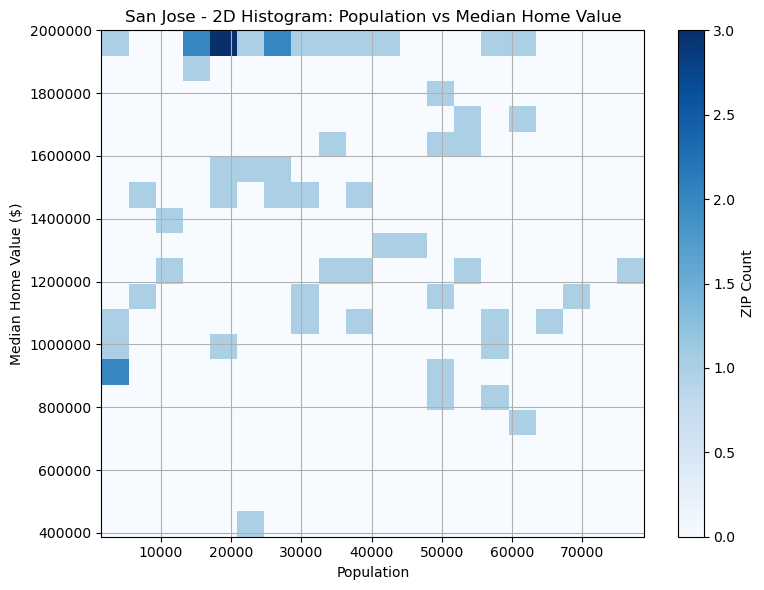

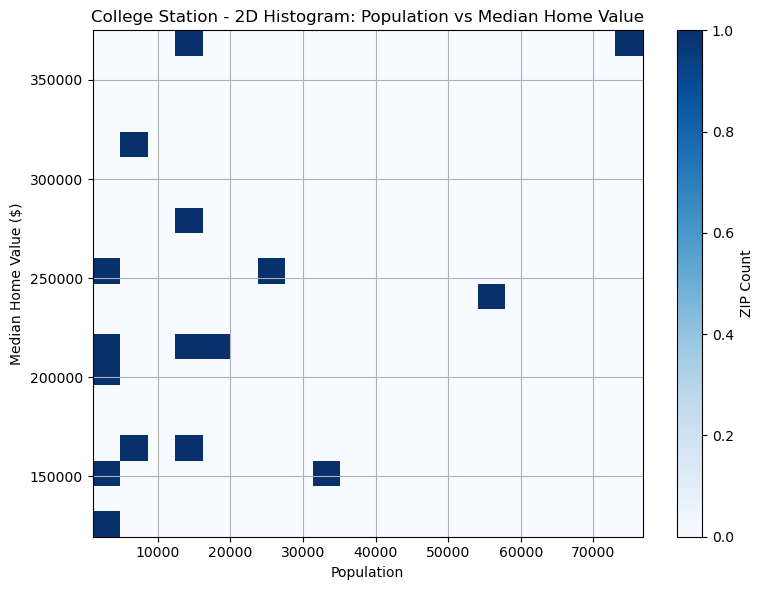

In [ ]:
# ZIP-months and ZIPs with longer histories were over-weighted.
census = pd.read_csv('data/processed/census_zcta.csv')
cities = ['los_angeles', 'san_jose', 'college_station']

def prettify(metro):
    return " ".join([w.capitalize() for w in metro.split('_')])

for metro in cities:
    metro_dat_clean = census[census['metro_key'] == metro].dropna(subset=['population', 'median_home_value'])
    plt.figure(figsize=(8,6))
    plt.hist2d(metro_dat_clean['population'], metro_dat_clean['median_home_value'], bins=(20,20), cmap="Blues")
    plt.colorbar(label='ZIP Count')

    plt.ticklabel_format(style='plain', axis='x')
    plt.ticklabel_format(style='plain', axis='y')

    plt.xlabel('Population')
    plt.ylabel('Median Home Value ($)')
    plt.title(f'{prettify(metro)} - 2D Histogram: Population vs Median Home Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Median House Price per Sqr Ft over time

Hotness Score vs Days on Market


Hotness score uses a mix of supply and demand scores. It measures the competitiveness of real estate markets.

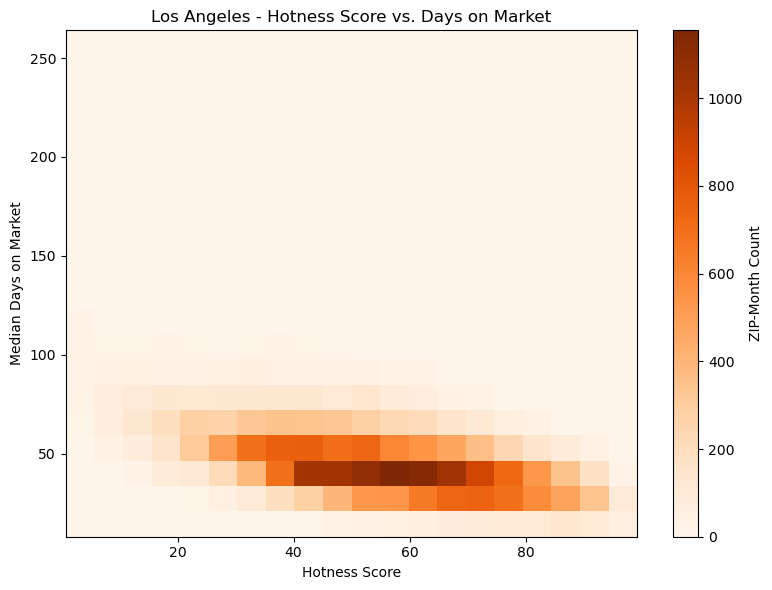

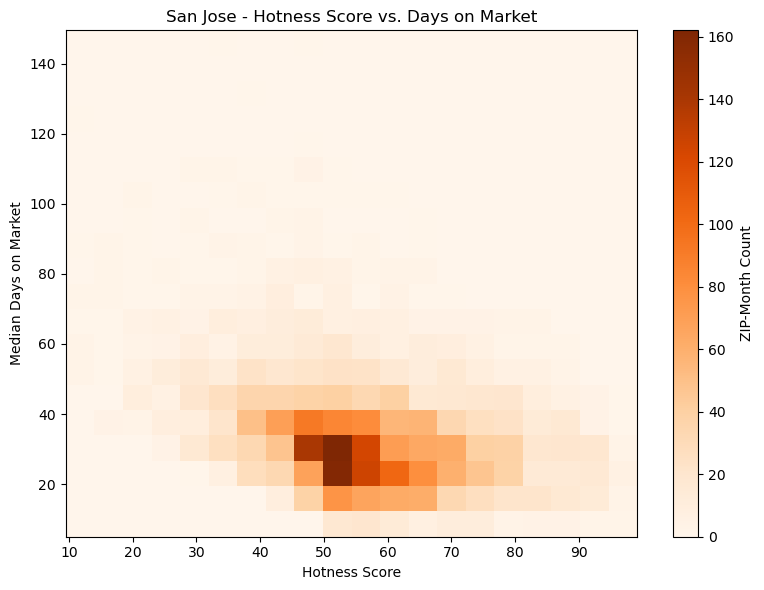

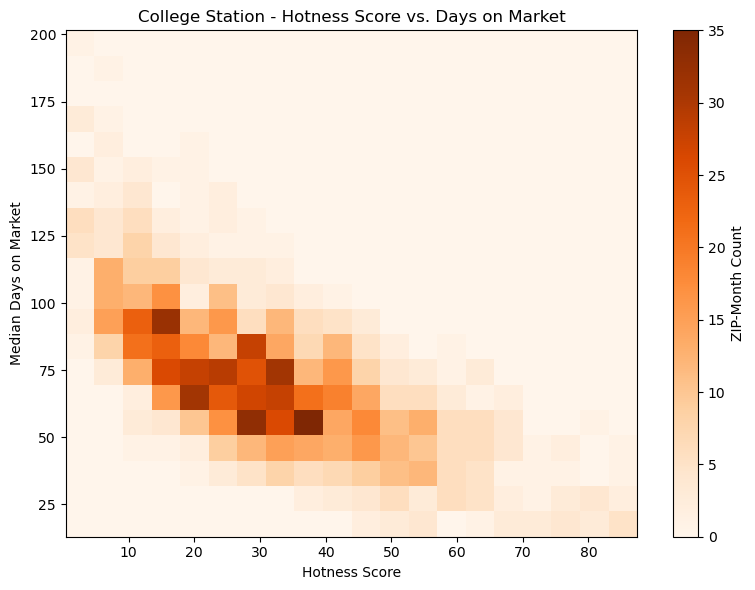

In [10]:
hotness = pd.read_csv("data/processed/realtor_hotness_zip_monthly.csv")
cities = ['los_angeles', 'san_jose', 'college_station']

for metro in cities:
    data = hotness[hotness['metro_key'] == metro].dropna(subset=['hotness_score', 'median_days_on_market'])
    plt.figure(figsize=(8,6))
    plt.hist2d(
        data['hotness_score'],
        data['median_days_on_market'],
        bins=(20, 20), cmap="Oranges"
    )
    plt.colorbar(label='ZIP-Month Count')
    plt.xlabel('Hotness Score')
    plt.ylabel('Median Days on Market')
    plt.title(f"{' '.join(metro.split('_')).title()} - Hotness Score vs. Days on Market")
    plt.tight_layout()
    plt.show()

Market Hotness over months

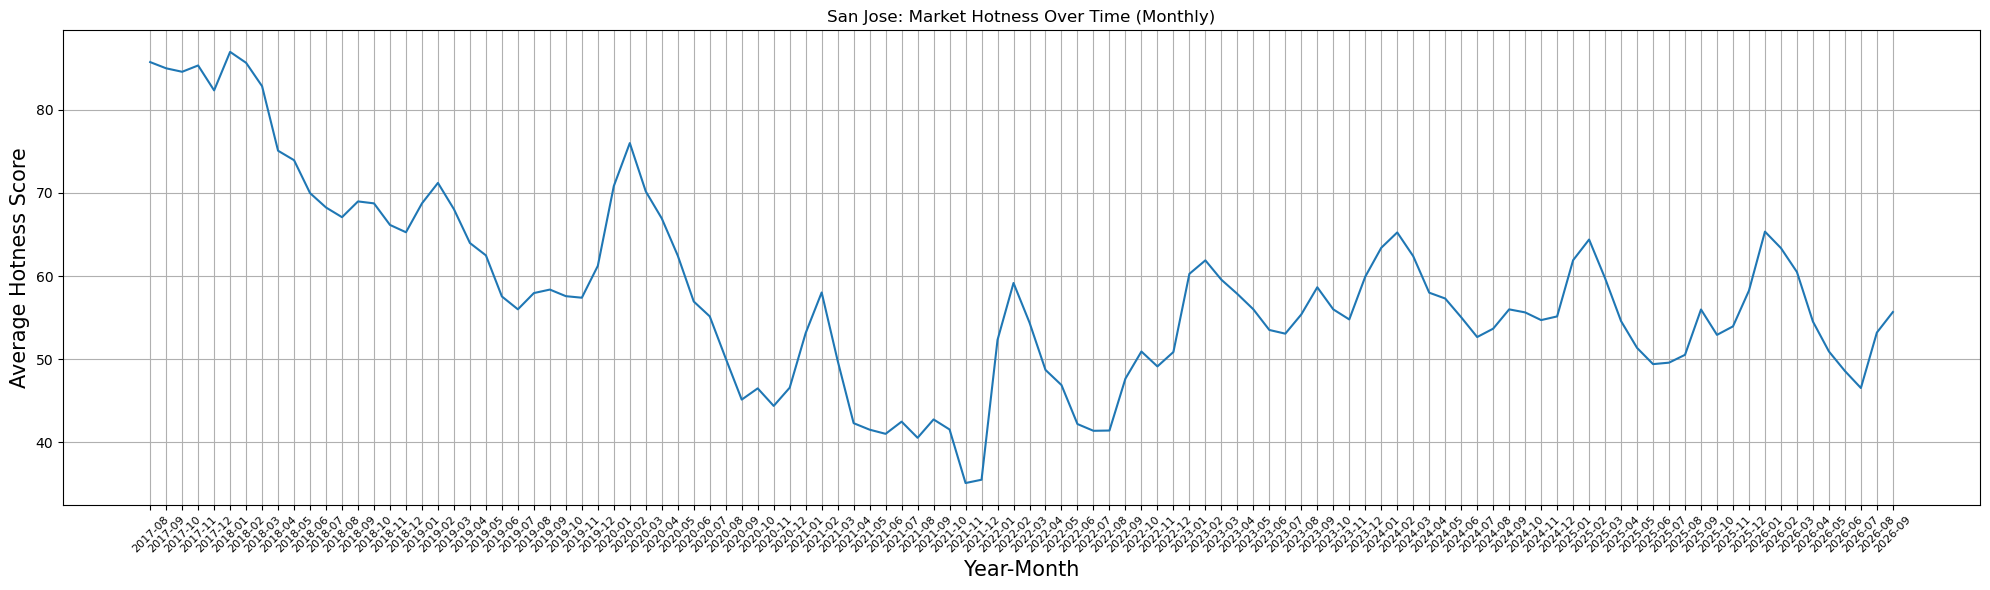

In [12]:

hotness = pd.read_csv("data/processed/realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'san_jose'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('San Jose: Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

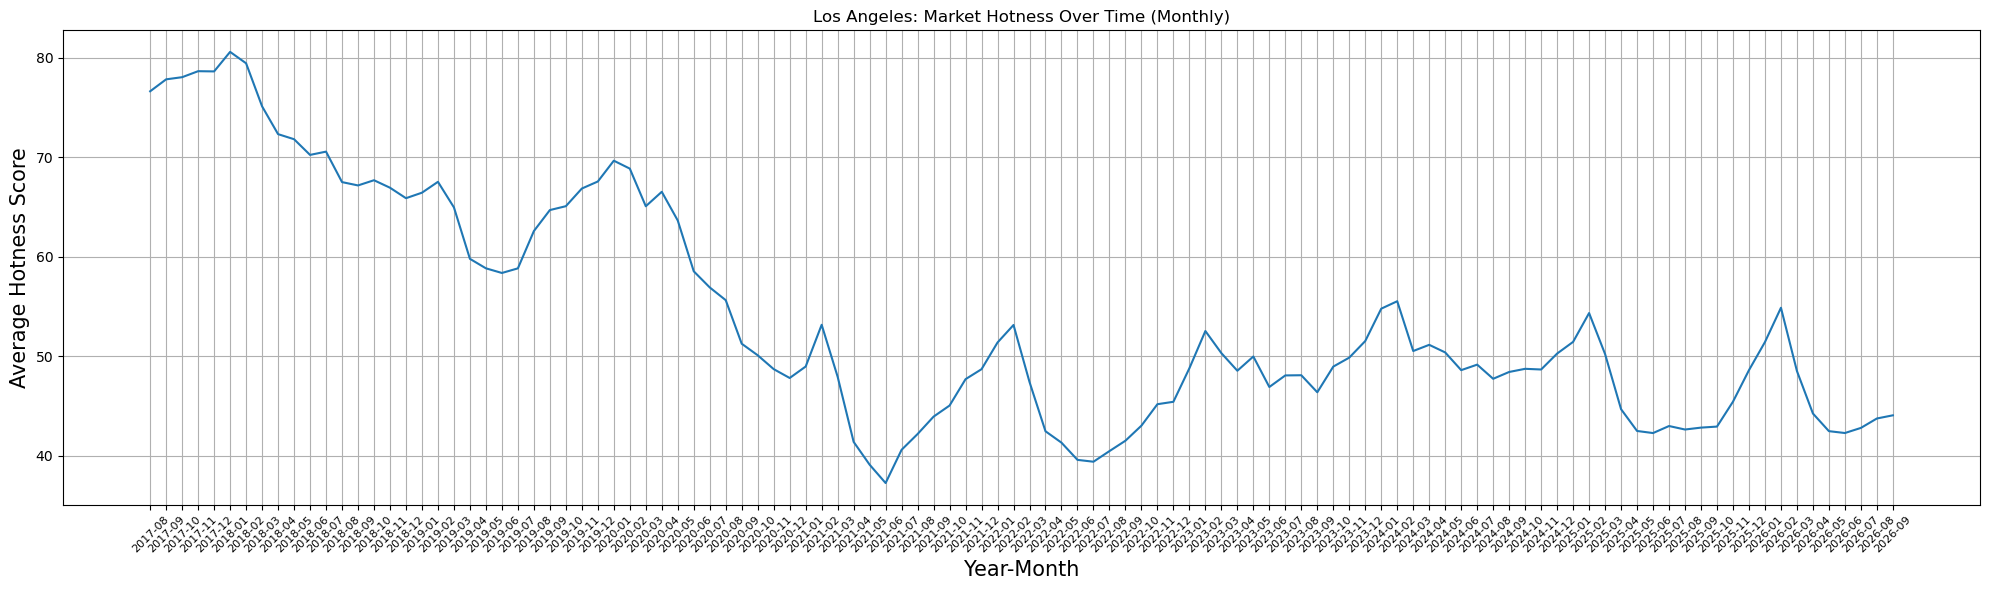

In [14]:


hotness = pd.read_csv("data/processed/realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'los_angeles'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('Los Angeles: Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

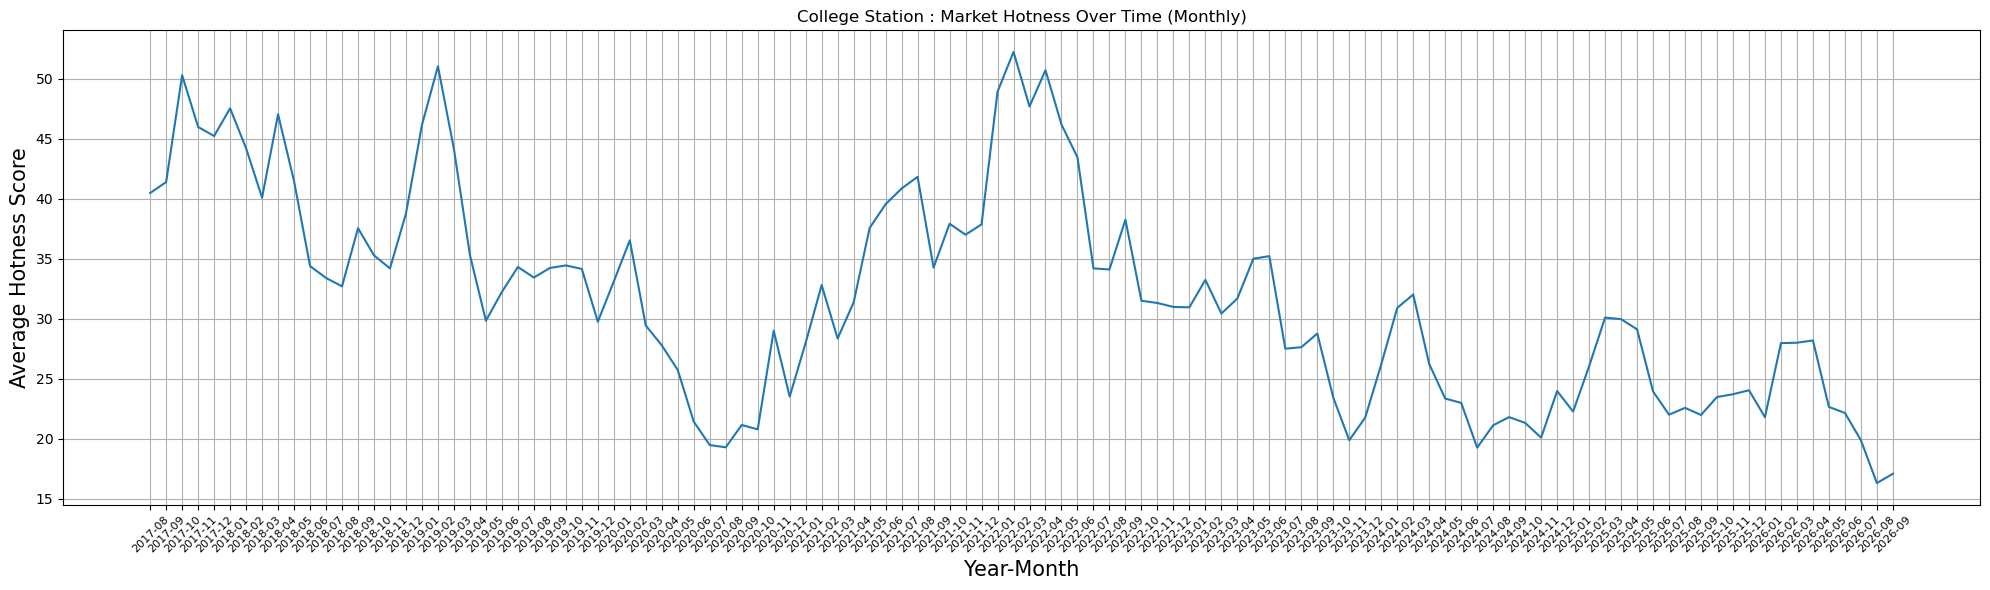

In [16]:


hotness = pd.read_csv("data/processed/realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'college_station'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('College Station : Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

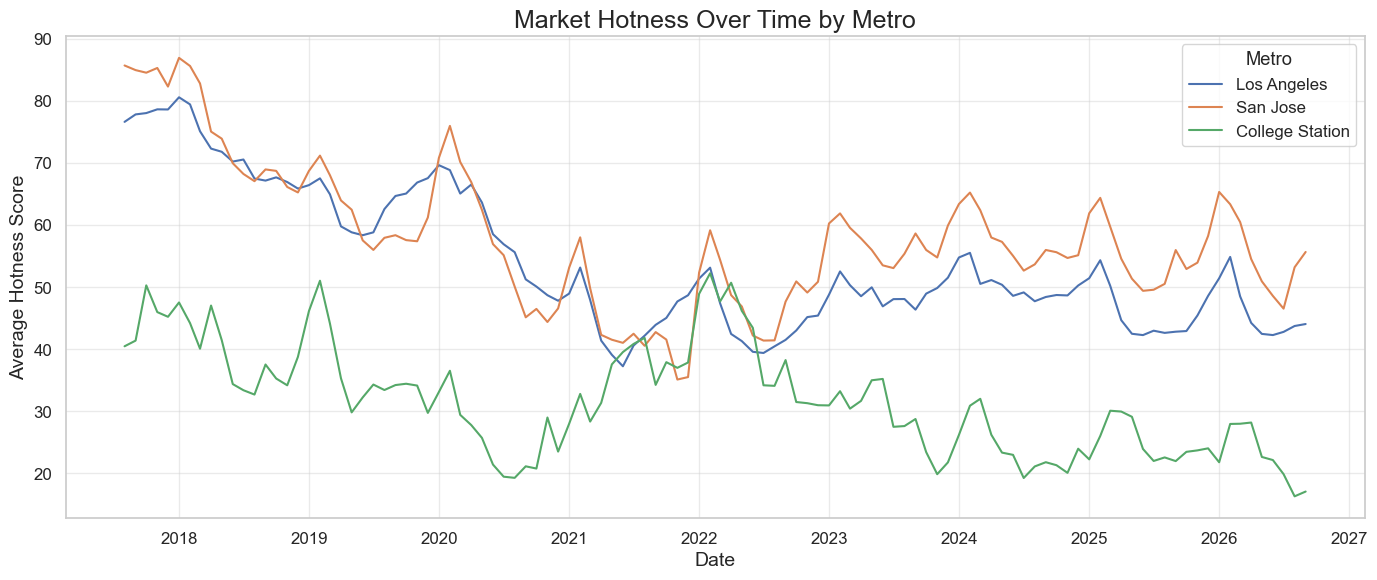

In [40]:
hotness['date'] = pd.to_datetime(hotness['date'])

monthly_hotness = (
    hotness[hotness['metro_key'].isin(metros)]
    .groupby(['date', 'metro_key'], as_index=False)['hotness_score']
    .mean()
)

plt.figure(figsize=(14, 6))

for metro in metros:
    data = monthly_hotness[monthly_hotness['metro_key'] == metro].sort_values('date')
    plt.plot(data['date'], data['hotness_score'], label=metro.replace('_', ' ').title())

plt.xlabel('Date')
plt.ylabel('Average Hotness Score')
plt.title('Market Hotness Over Time by Metro')
plt.legend(title='Metro')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

Median Listing Price over time

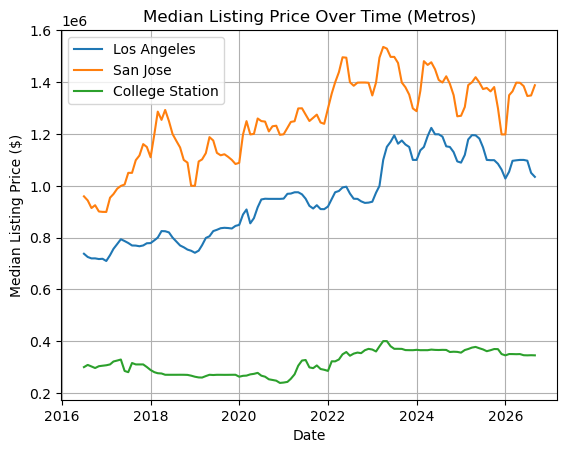

In [18]:
metro = pd.read_csv('data/processed/realtor_metro_monthly.csv')

metros = ['los_angeles', 'san_jose', 'college_station']

for m in metros:
    mdf = metro[metro['metro_key'] == m]
    plt.plot(pd.to_datetime(mdf['date']), mdf['median_listing_price'], label=m.title().replace('_', ' '))

plt.xlabel("Date")
plt.ylabel("Median Listing Price ($)")
plt.title("Median Listing Price Over Time (Metros)")
plt.legend()
plt.grid(True)
plt.show()

Population  vs Median Household income 

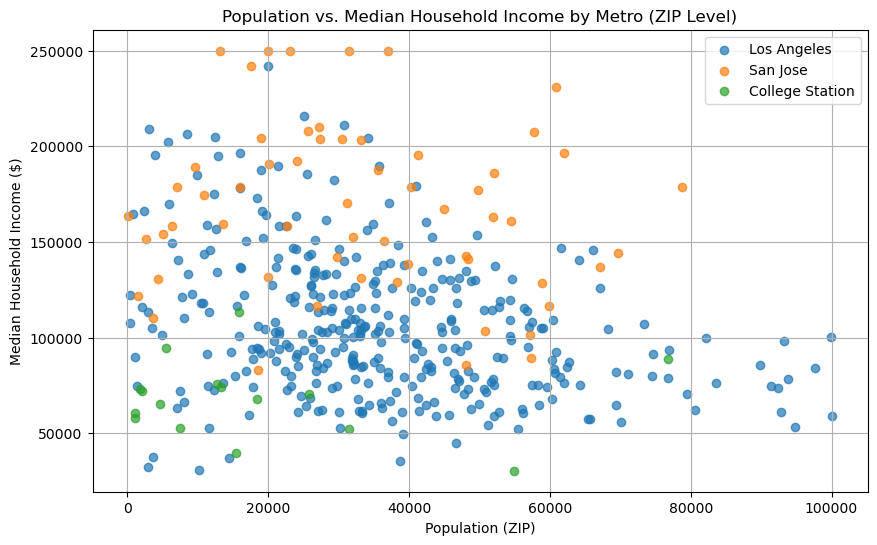

In [20]:


# Load your census data
census = pd.read_csv('data/processed/census_zcta.csv')  # Use the correct file path if different

metros = {
    'los_angeles': 'Los Angeles',
    'san_jose': 'San Jose',
    'college_station': 'College Station'
}

plt.figure(figsize=(10, 6))

for key, label in metros.items():
    df = census[census['metro_key'] == key]
    plt.scatter(df['population'], df['median_household_income'], label=label, alpha=0.7)

plt.xlabel("Population (ZIP)")
plt.ylabel("Median Household Income ($)")
plt.title("Population vs. Median Household Income by Metro (ZIP Level)")
plt.legend()
plt.grid(True)
plt.show()

Population Density vs Median Home Value

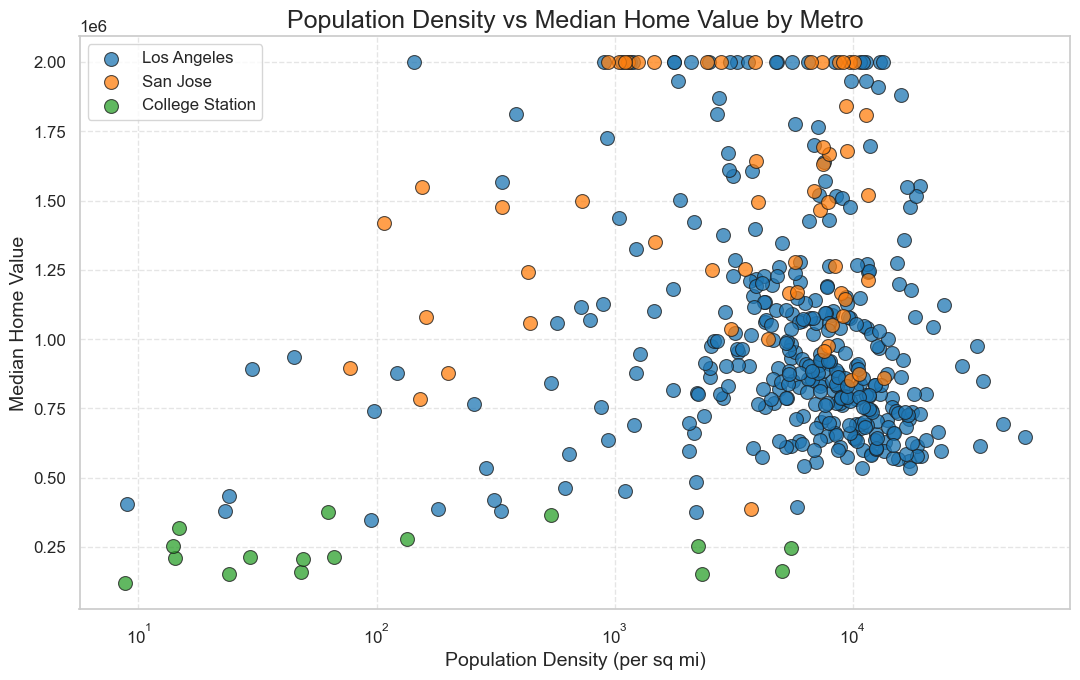

In [22]:


census = pd.read_csv('data/processed/census_zcta.csv')
metros = ['los_angeles', 'san_jose', 'college_station']

sns.set(style='whitegrid', font_scale=1.1)
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 14


#Format the pricing for cleaner view.
def price_fmt(x, pos):
    'Formatter for prices with commas'
    return '${:,.0f}'.format(x)


fig, ax = plt.subplots(figsize=(11, 7))
colors = sns.color_palette('tab10', len(metros))
for idx, metro in enumerate(metros):
    df = census[census['metro_key']==metro]
    sns.scatterplot(data=df, x='pop_density_per_sqmi', y='median_home_value',
                    label=metro.replace('_',' ').title(), color=colors[idx], s=100, edgecolor='k', alpha=0.75, ax=ax)
ax.set_xscale('log')
ax.set_title('Population Density vs Median Home Value by Metro')
ax.set_xlabel('Population Density (per sq mi)')
ax.set_ylabel('Median Home Value')
ax.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

Affordability Ratio

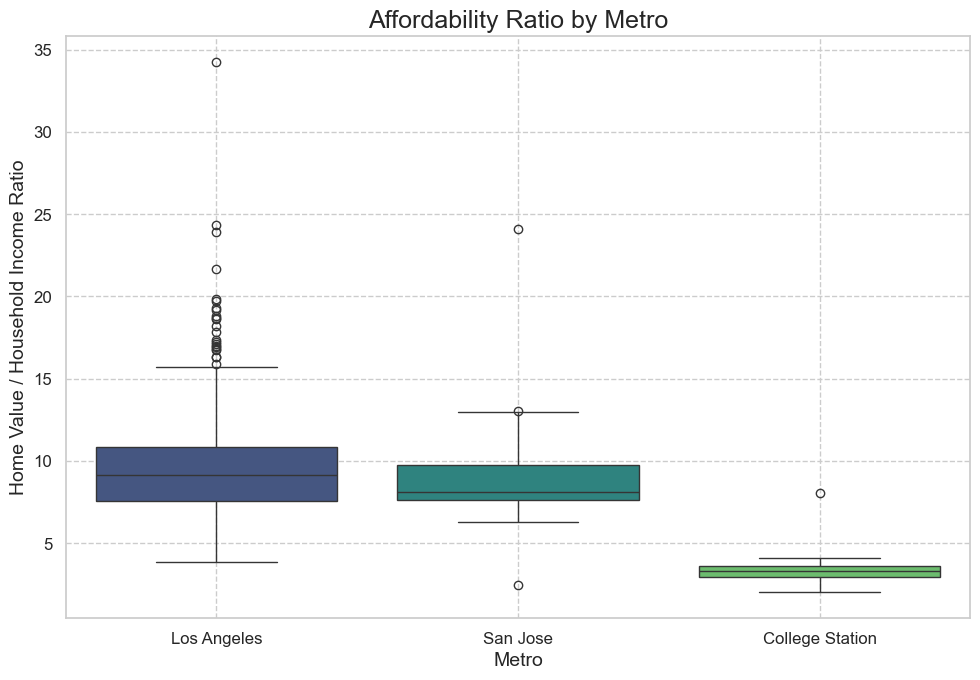

Price-to-income ratio by metro (ZIP-level):
                 count   25%   50%    75%
metro_key                                
los_angeles      359.0  7.56  9.17  10.86
san_jose          57.0  7.61  8.11   9.79
college_station   16.0  2.93  3.33   3.64

ZIPs at the ACS top-code (ratio is unreliable for these):
                 zips  home_value_at_cap  income_at_cap
metro_key                                              
los_angeles       360                 22              0
san_jose           59                 15              5
college_station    16                  0              0


In [ ]:
metros = ['los_angeles', 'san_jose', 'college_station']
census['price_to_income'] = census['median_home_value'] / census['median_household_income']

fig, ax = plt.subplots(figsize=(10,7))
sns.boxplot(x='metro_key', y='price_to_income', data=census, order=metros,
            hue='metro_key', hue_order=metros, palette='viridis', legend=False, ax=ax)
ax.set_xticks(range(len(metros)))
ax.set_xticklabels([m.replace('_',' ').title() for m in metros])
ax.set_ylabel('Home Value / Household Income Ratio')
ax.set_xlabel('Metro')
ax.set_title('Affordability Ratio by Metro')
ax.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

# Numbers for the report
print("Price-to-income ratio by metro (ZIP-level):")
print(census.groupby('metro_key')['price_to_income'].describe()
      .loc[metros, ['count', '25%', '50%', '75%']].round(2))

# ACS top-codes values: home value at $2,000,001 and income at $250,001. ZIPs at the cap make
# expensive metros look *more* affordable than they are. Report how many are affected.
caps = census.groupby('metro_key').agg(
    zips=('zip', 'count'),
    home_value_at_cap=('median_home_value', lambda s: int((s >= 2_000_000).sum())),
    income_at_cap=('median_household_income', lambda s: int((s >= 250_000).sum())),
).loc[metros]
print("\nZIPs at the ACS top-code (ratio is unreliable for these):")
print(caps)

Population vs Median Gross Rent

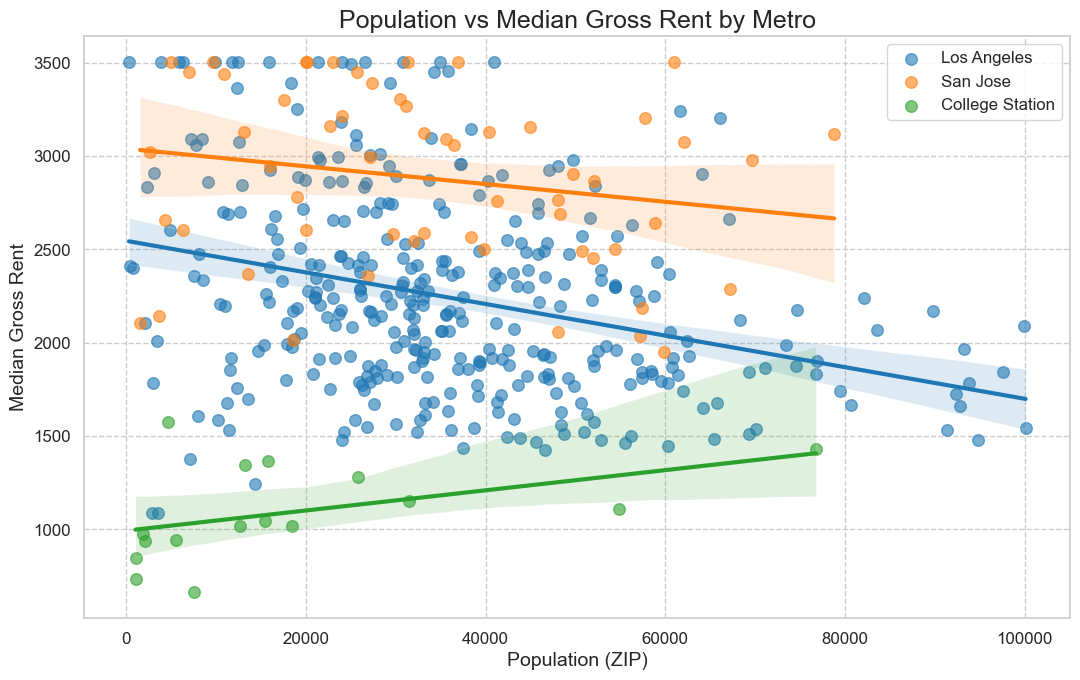

In [24]:
fig, ax = plt.subplots(figsize=(11, 7))
for idx, metro in enumerate(metros):
    df = census[census['metro_key']==metro]
    sns.regplot(x='population', y='median_gross_rent', data=df, scatter_kws={'s':70, 'alpha':0.6}, label=metro.replace('_',' ').title(), color=colors[idx], ax=ax, line_kws={'lw':3})
ax.set_title('Population vs Median Gross Rent by Metro')
ax.set_xlabel('Population (ZIP)')
ax.set_ylabel('Median Gross Rent')
ax.grid(True, linestyle='--')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

$\text{Some Geospatial Data}$

In [ ]:
import plotly.express as px

census = pd.read_csv('data/processed/census_zcta.csv')
fig = px.scatter_mapbox(
    census.dropna(subset=['lat', 'lon']),
    lat="lat",
    lon="lon",
    color="pop_density_per_sqmi",
    hover_data=["zip", "median_home_value", "population", "median_household_income"],
    mapbox_style="open-street-map",
    center={"lat": 34.05, "lon": -118.25},
    zoom=8,
    opacity=0.7,
    color_continuous_scale="Viridis"
)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

$\text{\Large{Section 2:} {Forecasting}}$

Here we do a Forecasting with specific zip codes from each Metropolitan( 4 per each city).


Model to be used: SARIMAX (on log price, with a 12-month backtest).

San Jose: Using zip codes from Santa Clara

- 94022(Los Altos , Santa Clara County)

- 95054 (Santa Clara, Santa Clara County)

- 94040 (Mountain View , Santa Clara County)

- 95118 (San Jose, Santa Clara County)

*Note: three of these four are high-end Silicon Valley ZIPs, so this group is pricier than the San Jose metro as a whole. The ZIP check cell below quantifies this; either describe the group as "Silicon Valley / Santa Clara County" in the report or swap in more San Jose-city ZIPs.*


Los Angeles zip codes from Los Angeles:

- 90004

- 90005

- 90232

- 90059


College Station zip codes (CORRECTED: 77087 is a Houston ZIP and 76629 is Bremond, so the original group contained no College Station ZIPs):

- 77840 (College Station)

- 77845 (College Station)

- 77801 (Bryan)

- 77802 (Bryan)

Features to consider

1) population

2) median household income

3) population density per square mile

4) hotness score

5) median days on market

6) median gross rent

**CORRECTION:** features 1, 2, 3 and 6 come from a single Census snapshot (ACS 5-year), so each ZIP has one value that never changes over time. In a time-series model a constant input carries no information (after standardizing it is all zeros), so the forecast model uses only the **time-varying** features: hotness score and median days on market. Population, income, density and rent are used in Section 3 instead, where we compare ZIPs *with each other* rather than over time.

In [28]:
#Import the needed libraries
from statsmodels.tsa.statespace.sarimax import SARIMAX as smx
import numpy as np
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler

In [30]:

# Load data, this is the main dataset we will be using.
df = pd.read_csv('data/processed/zip_month_panel.csv')


In [31]:


# List of target ZIPs for San Jose,Los Angeles, College station
sj_zips = [94022, 95054, 94040, 95118]
la_zips = [90004 , 90005,90232, 90059]
# CORRECTED: was [76629, 77801, 77802, 77087]. 77087 is in Houston (not in our data, so it was
# silently dropped) and 76629 is Bremond. These are College Station (77840, 77845) and Bryan.
cs_zips = [77840, 77845, 77801, 77802]




#Make sure to convert to datetime.
df['month'] =pd.to_datetime(df['month'])

#Make sure to convert the date for the hotness metric too.
hotness['date'] = pd.to_datetime(hotness['date'])


# Standardize ZIP-code types.
df['zip'] = pd.to_numeric(df['zip']).astype('Int64')
hotness['zip'] = pd.to_numeric(hotness['zip']).astype('Int64')


#Merge,safe for no nulls.
df = df.merge(
    hotness[['zip', 'date', 'hotness_score']],
    left_on=['zip', 'month'],
    right_on=['zip', 'date'],
    how='left',
     validate='many_to_one'
)

#Drop redundant date column.
df = df.drop(columns=['date'])

#Interpolate Null hotness score values, just to avoid any weird errors later on.
df['hotness_score'] = df.groupby('zip')['hotness_score'].transform(lambda x: x.interpolate().ffill().bfill())




In [32]:
#This is the target feature
targ = 'rdc_median_listing_price'

#features for forecast
features = ['population', 'median_household_income', 'pop_density_per_sqmi', 'hotness_score', 
           'rdc_median_days_on_market', 'median_gross_rent']




#Numeric columns
numeric_columns = features + [targ]


#Convert to numeric
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')



# Interpolate within each ZIP code
df = df.sort_values(['zip', 'month'])
for col in features:

    df[col] = df.groupby('zip')[col].transform(
        
        lambda x: x.interpolate(
            limit_direction='both'
        ).ffill().bfill()
    )




#Filter the san jose zip codes for the forecasting 
sj_df = df[df['zip'].isin(sj_zips)].copy()
la_df = df[df['zip'].isin(la_zips)].copy()
cs_df= df[df['zip'].isin(cs_zips)].copy()



#Start year for forecast, August 1st 2017
sj_df = sj_df[sj_df['month'] >= '2017-08-01']
la_df = la_df[la_df['month'] >= '2017-08-01']
cs_df = cs_df[cs_df['month'] >= '2017-08-01']


#Function to combine the regional data together(San Jose, Los Angeles, College Station), help of chat.tamu.ai in this function
def aggregate_region(data):

    # Ensure chronological ordering
    data = data.sort_values(['zip', 'month']).copy()

    

    # Aggregate ZIP codes by month(Keep in mind to have the mean since we are aiming to predict a variable that is already an average).
    regional_data = data.groupby('month').agg({
        'rdc_median_listing_price': 'mean',
        'population': 'sum',
        'median_household_income': 'mean',
        'pop_density_per_sqmi': 'mean',
        'hotness_score': 'mean',
        'rdc_median_days_on_market': 'mean',
        'median_gross_rent': 'mean'

    })

    # Count ZIP codes contributing to each month's target
    # zip_counts = (
    #     data.groupby('month')
    #     .apply(
    #         lambda x: x.loc[
    #             x['rdc_median_listing_price'].notna(), 'zip'
    #         ].nunique(),
    #         include_groups=False
    #     )
    # )

    # Check geographic coverage
    # print("ZIP-code coverage:")
    # print(zip_counts.value_counts().sort_index())



    # Create a complete monthly index.
    full_index = pd.date_range(
        start=regional_data.index.min(),
        end=regional_data.index.max(),
        freq='MS'
    )


    regional_data = regional_data.reindex(full_index)
    regional_data.index.name = 'month'



    # Fill missing predictor values after aggregation.
    regional_data[features] = (

        regional_data[features]
        .interpolate(method='time')
        .ffill()
        .bfill()
    )
    return regional_data
  

# Aggregate all three regions.
sj_data = aggregate_region(sj_df)
la_data = aggregate_region(la_df)
cs_data = aggregate_region(cs_df)


In [ ]:
selections = {'san_jose': sj_zips, 'los_angeles': la_zips, 'college_station': cs_zips}
last_12 = df[df['month'] > df['month'].max() - pd.DateOffset(months=12)]

rows = []
for metro, zips in selections.items():
    in_metro = set(df.loc[df['metro_key'] == metro, 'zip'].dropna().astype(int))
    missing = sorted(set(zips) - in_metro)
    if missing:
        raise ValueError(f"{metro}: ZIPs {missing} are not in this metro's data - replace them")
    zip_prices = last_12[last_12['metro_key'] == metro].groupby('zip')[targ].median().dropna()
    chosen = zip_prices[zip_prices.index.isin(zips)]
    rows.append({
        'metro': metro,
        'chosen_group_mean_price': round(chosen.mean()),
        'metro_median_zip_price': round(zip_prices.median()),
        'chosen_vs_metro': f"{chosen.mean() / zip_prices.median():.2f}x",
        'chosen_price_percentiles': [int(round((zip_prices < p).mean() * 100)) for p in chosen],
    })
print("Median listing price over the last 12 months (chosen ZIPs vs. all ZIPs in the metro):")
print(pd.DataFrame(rows).set_index('metro').to_string())

Median listing price over the last 12 months (chosen ZIPs vs. all ZIPs in the metro):
                 chosen_group_mean_price  metro_median_zip_price chosen_vs_metro chosen_price_percentiles
metro                                                                                                    
san_jose                         2034027                 1359664           1.50x         [93, 51, 29, 59]
los_angeles                      1227872                  967962           1.27x         [76, 26, 11, 90]
college_station                   330706                  302850           1.09x          [6, 69, 50, 75]


In [ ]:
#  1) Only time-varying inputs are used (hotness, days on market). The Census features were
#     constant over time, so they became all-zero columns and contributed nothing.
#  2) The model is fit on log(price). Forecasts and 95% intervals are converted back to dollars,
#     so they can no longer go negative. (exp of the log forecast = median forecast.)
#  3) 12-month backtest: fit on everything except the last 12 months, forecast those months,
#     and score against what actually happened. The original RMSE (result.mse) was in-sample,
#     which says how well the model fits past data, not how well it forecasts.
#  4) Two naive baselines for comparison. If SARIMAX can't beat them, say so in the report.

regions = {
    'San Jose': sj_data,
    'Los Angeles': la_data,
    'College Station': cs_data
}

model_features = ['hotness_score', 'rdc_median_days_on_market']
holdout = 12   # months held out for the backtest
future = 36    # 3-year forecast
order, seasonal_order = (1, 1, 1), (1, 1, 1, 12)


def fit_sarimax(y_log, exog):
    scaler = StandardScaler().fit(exog)
    exog_scaled = pd.DataFrame(scaler.transform(exog), index=exog.index, columns=exog.columns)
    result = smx(y_log, exog=exog_scaled, order=order, seasonal_order=seasonal_order,
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=500)
    return result, scaler


def forecast_dollars(result, scaler, exog_last, index):
    """Forecast len(index) months, holding the inputs at their last known values."""
    exog_future = pd.DataFrame([exog_last.values] * len(index), index=index, columns=exog_last.index)
    exog_future = pd.DataFrame(scaler.transform(exog_future), index=index, columns=exog_last.index)
    fc = result.get_forecast(steps=len(index), exog=exog_future)
    ci = fc.conf_int(alpha=0.05)
    return pd.DataFrame({
        'forecast': np.exp(fc.predicted_mean.to_numpy()),
        'lower_95': np.exp(ci.iloc[:, 0].to_numpy()),
        'upper_95': np.exp(ci.iloc[:, 1].to_numpy()),
    }, index=index)


regional_results, regional_forecasts, regional_backtests, metrics = {}, {}, {}, []

for region, data in regions.items():
    print(f'Fitting SARIMAX: {region}')
    y = data[targ].astype(float)
    y = y.loc[:y.last_valid_index()]                 # drop trailing months with no price
    exog = data.loc[y.index, model_features].astype(float)

    # ---- 1. Backtest on the last `holdout` months ----------------------------------- #
    res_bt, sc_bt = fit_sarimax(np.log(y.iloc[:-holdout]), exog.iloc[:-holdout])
    bt = forecast_dollars(res_bt, sc_bt, exog.iloc[-holdout - 1], y.index[-holdout:])
    bt['actual'] = y.iloc[-holdout:].to_numpy()
    bt['naive_last_value'] = y.iloc[-holdout - 1]                       # "no change"
    bt['naive_seasonal'] = y.shift(12).iloc[-holdout:].to_numpy()       # same month last year
    regional_backtests[region] = bt

    ok = bt['actual'].notna()
    a = bt.loc[ok, 'actual']
    mape = lambda col: (np.abs(bt.loc[ok, col] - a) / a).mean() * 100
    rmse = lambda col: np.sqrt(((bt.loc[ok, col] - a) ** 2).mean())
    coverage = ((a >= bt.loc[ok, 'lower_95']) & (a <= bt.loc[ok, 'upper_95'])).mean() * 100

    # ---- 2. Refit on all data and forecast `future` months -------------------------- #
    result, scaler = fit_sarimax(np.log(y), exog)
    future_index = pd.date_range(start=y.index[-1], periods=future + 1, freq='MS')[1:]
    fc = forecast_dollars(result, scaler, exog.iloc[-1], future_index)
    regional_results[region] = {'model': result, 'scaler': scaler}
    regional_forecasts[region] = fc

    last = y.iloc[-1]
    metrics.append({
        'region': region,
        'months_of_data': int(y.notna().sum()),
        'backtest_MAPE_%': round(mape('forecast'), 1),
        'naive_last_value_MAPE_%': round(mape('naive_last_value'), 1),
        'naive_seasonal_MAPE_%': round(mape('naive_seasonal'), 1),
        'backtest_RMSE_$': round(rmse('forecast')),
        'actuals_inside_95%_interval_%': round(coverage),
        'last_observed_$': round(last),
        'forecast_12m_$': round(fc['forecast'].iloc[11]),
        'forecast_36m_$': round(fc['forecast'].iloc[-1]),
        'change_36m_%': round((fc['forecast'].iloc[-1] / last - 1) * 100, 1),
        'AIC (diagnostic only)': round(result.aic, 1),
    })

metrics_df = pd.DataFrame(metrics).set_index('region')
print()
print(metrics_df.T.to_string())

Fitting SARIMAX: San Jose
Fitting SARIMAX: Los Angeles
Fitting SARIMAX: College Station

region                          San Jose  Los Angeles  College Station
months_of_data                     110.0        110.0            110.0
backtest_MAPE_%                     15.8          7.5              7.8
naive_last_value_MAPE_%             12.8          4.7              4.7
naive_seasonal_MAPE_%               13.7          4.8              7.7
backtest_RMSE_$                 355385.0     111622.0          31911.0
actuals_inside_95%_interval_%      100.0         92.0            100.0
last_observed_$                2130062.0    1163438.0         303750.0
forecast_12m_$                 2087456.0    1243627.0         315497.0
forecast_36m_$                 2080219.0    1276382.0         332754.0
change_36m_%                        -2.3          9.7              9.5
AIC (diagnostic only)             -128.7       -201.3           -292.8


$\textbf{Brief Model Stats}$

**How to read the table printed above (use these numbers in the report):**

- **backtest_MAPE_%**: average % error when the model forecast the last 12 months *without seeing them*. This is the accuracy number to report.
- **naive_..._MAPE_%**: the same error for two simple rules: "price stays at last month's value" and "price equals the same month last year". If SARIMAX isn't clearly lower than these, the model isn't adding predictive value. Say so; that is a legitimate finding.
- **actuals_inside_95%_interval_%**: should be near 95%. Much lower means the intervals are too narrow (overconfident).
- **forecast_12m / 36m and change_36m_%**: the median forecast in dollars and the implied change from the last observed month.
- **AIC**: for comparing model settings *within one region* only. It has no units and can't be compared across regions, because each region's prices are on a different scale.

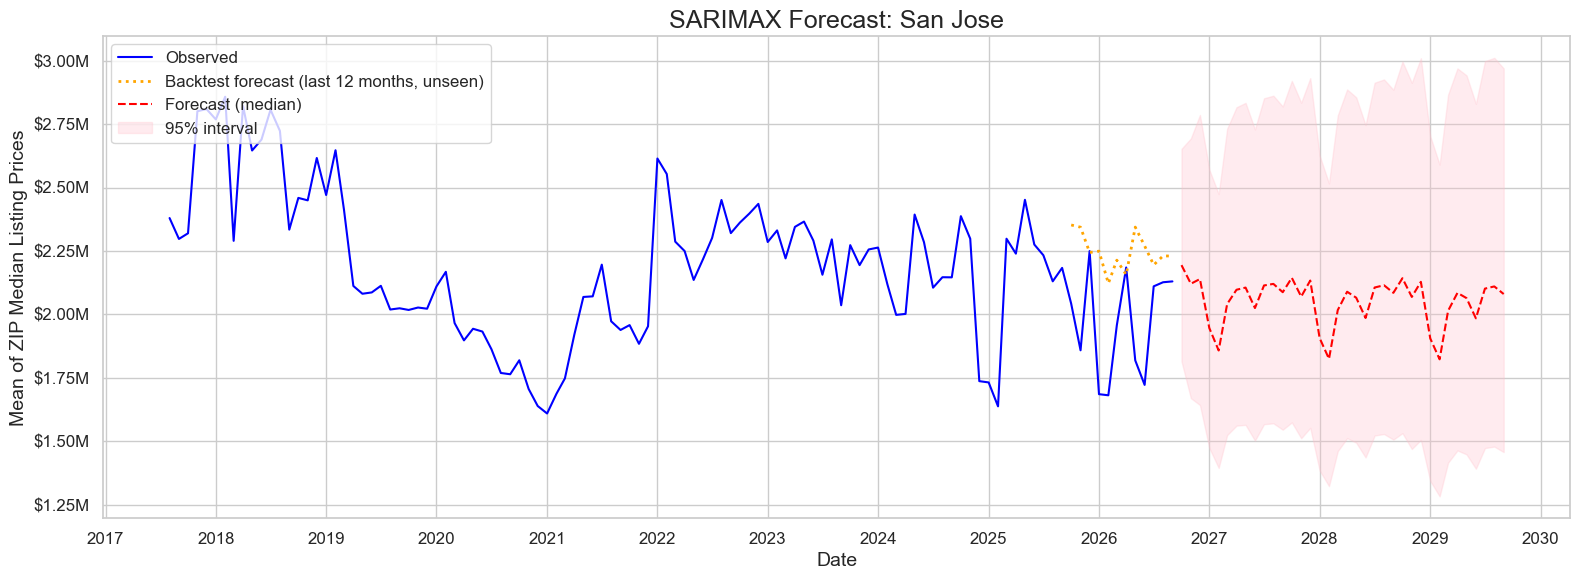

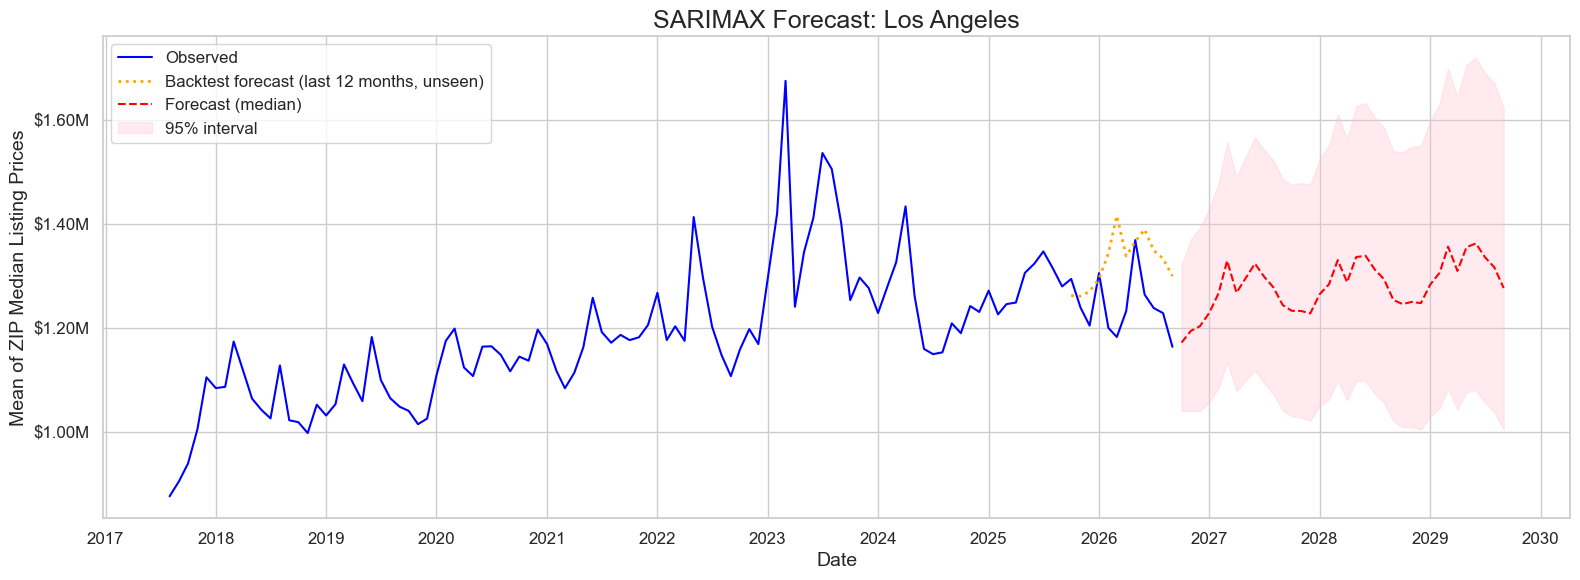

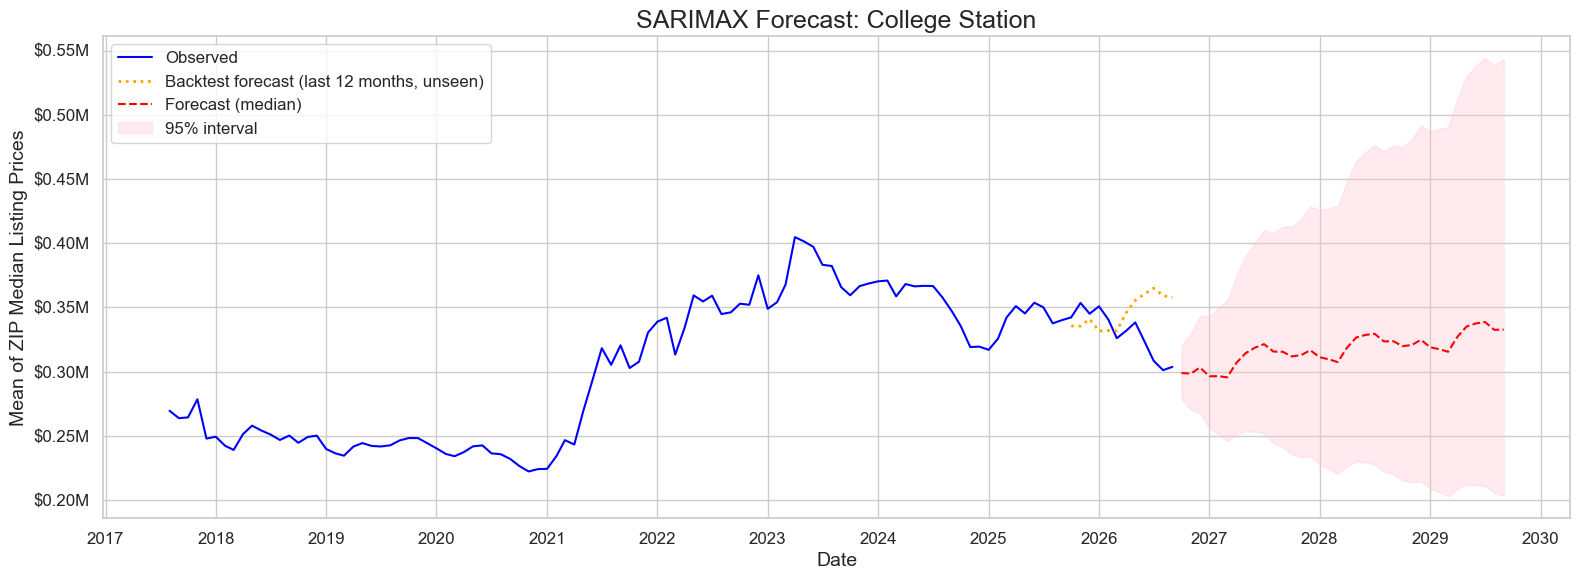

In [ ]:
# the y-axis as $ in millions (the old label said "millions" but the axis wasn't scaled).
from matplotlib.ticker import FuncFormatter
millions = FuncFormatter(lambda x, pos: f'${x / 1e6:.2f}M')

for region, data in regions.items():
    fc = regional_forecasts[region]
    bt = regional_backtests[region]

    plt.figure(figsize=(16, 6))
    plt.plot(data.index, data[targ], color='blue', label='Observed')
    plt.plot(bt.index, bt['forecast'], color='orange', linestyle=':', linewidth=2,
             label='Backtest forecast (last 12 months, unseen)')
    plt.plot(fc.index, fc['forecast'], color='red', linestyle='--', label='Forecast (median)')
    plt.fill_between(fc.index, fc['lower_95'], fc['upper_95'], color='pink', alpha=0.3, label='95% interval')

    plt.xlabel('Date')
    plt.ylabel('Mean of ZIP Median Listing Prices')
    plt.title(f'SARIMAX Forecast: {region}')
    plt.legend(loc='upper left')
    plt.gca().yaxis.set_major_formatter(millions)
    plt.gca().xaxis.set_major_locator(mdates.YearLocator())
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    plt.show()

$\text{\Large{Section 3:} {Research Questions}}$

Two questions the case study has to answer that Sections 1 and 2 don't yet:

1. **What household income is needed to afford a 2,500 sqft house in each area?**
2. **Do denser areas have less volatile house prices?** We test this at the ZIP level (435 ZIPs) instead of comparing three cities, because three data points can't support a statistical conclusion.

In [ ]:
# Price estimate = ZIP median list price per sqft (median of the last 12 months, to smooth
# seasonality and thin months) x 2,500. Then: monthly mortgage payment + property tax + insurance,
# and the income at which that is 28% of gross income (standard front-end lending guideline).

panel = pd.read_csv('data/processed/zip_month_panel.csv', dtype={'zip': str}, parse_dates=['month'])
census = pd.read_csv('data/processed/census_zcta.csv', dtype={'zip': str})
metros = ['los_angeles', 'san_jose', 'college_station']

# ---- Assumptions: edit these, and state them in the report ---------------------------- #
SQFT = 2500
DOWN_PAYMENT = 0.20         # 20% down, so no PMI
TERM_YEARS = 30
FRONT_END_DTI = 0.28        # housing costs <= 28% of gross income
PROPERTY_TAX = {'los_angeles': 0.012, 'san_jose': 0.012, 'college_station': 0.021}  # approx. effective rates
INSURANCE = 0.005           # homeowners insurance, share of home value per year (rough)
LOOKBACK_MONTHS = 12
# --------------------------------------------------------------------------------------- #

ppsf = 'rdc_median_listing_price_per_square_foot'
rate = panel.dropna(subset=['MORTGAGE30US']).sort_values('month')['MORTGAGE30US'].iloc[-1]
latest = panel['month'].max()
recent = panel[panel['month'] > latest - pd.DateOffset(months=LOOKBACK_MONTHS)]


def required_income(price, tax_rate, annual_rate_pct=rate):
    loan = price * (1 - DOWN_PAYMENT)
    r, n = annual_rate_pct / 100 / 12, TERM_YEARS * 12
    mortgage = loan * r / (1 - (1 + r) ** -n)
    tax_ins = price * (tax_rate + INSURANCE) / 12
    return 12 * (mortgage + tax_ins) / FRONT_END_DTI


zips = (recent.groupby(['zip', 'metro_key'])
        .agg(ppsf=(ppsf, 'median'), median_sqft=('rdc_median_square_feet', 'median'))
        .reset_index().dropna(subset=['ppsf']))
zips['price_2500sqft'] = zips['ppsf'] * SQFT
zips['required_income'] = [required_income(p, PROPERTY_TAX[m])
                           for p, m in zip(zips['price_2500sqft'], zips['metro_key'])]
zips = zips.merge(census[['zip', 'median_household_income']], on='zip', how='left')
zips['affordable'] = zips['median_household_income'] >= zips['required_income']

summary = zips.groupby('metro_key').agg(
    zips=('zip', 'count'),
    price_2500sqft=('price_2500sqft', 'median'),
    required_income=('required_income', 'median'),
    actual_median_income=('median_household_income', 'median'),
    share_of_zips_affordable=('affordable', 'mean'),
    typical_listing_sqft=('median_sqft', 'median'),
).loc[metros]
summary['required_vs_actual'] = summary['required_income'] / summary['actual_median_income']

print(f"30-yr mortgage rate used: {rate:.2f}%  (latest month in panel: {latest:%b %Y})\n")
fmt = summary.copy()
for c in ['price_2500sqft', 'required_income', 'actual_median_income']:
    fmt[c] = fmt[c].map('${:,.0f}'.format)
fmt['share_of_zips_affordable'] = (summary['share_of_zips_affordable'] * 100).round().astype(int).astype(str) + '%'
fmt['required_vs_actual'] = summary['required_vs_actual'].map('{:.1f}x'.format)
fmt['typical_listing_sqft'] = summary['typical_listing_sqft'].round().astype(int)
print(fmt.to_string())

print("\nCaveats for the report:")
print(" - List prices, not sale prices.")
print(" - $/sqft usually falls as homes get bigger. Where typical listings are much smaller than")
print("   2,500 sqft (see typical_listing_sqft), this method overstates the 2,500 sqft price.")
print(" - ACS income is capped at $250,001, so the richest ZIPs' affordability is understated.")

# Same numbers for the ZIPs used in the forecasts
showcase = [str(z) for z in [94022, 95054, 94040, 95118, 90004, 90005, 90232, 90059,
                             77840, 77845, 77801, 77802]]
show = zips[zips['zip'].isin(showcase)].set_index('zip')[
    ['metro_key', 'price_2500sqft', 'required_income', 'median_household_income', 'median_sqft']]
print("\nForecast ZIPs:")
print(show.round(0).to_string())

30-yr mortgage rate used: 6.86%  (latest month in panel: Sep 2026)

                 zips price_2500sqft required_income actual_median_income share_of_zips_affordable  typical_listing_sqft required_vs_actual
metro_key                                                                                                                                  
los_angeles       359     $1,563,750        $446,702             $101,455                       0%                  1570               4.4x
san_jose           59     $2,100,000        $599,888             $163,594                       0%                  1531               3.7x
college_station    16       $463,750        $147,381              $69,278                       0%                  1766               2.1x

Caveats for the report:
 - List prices, not sale prices.
 - $/sqft usually falls as homes get bigger. Where typical listings are much smaller than
   2,500 sqft (see typical_listing_sqft), this method overstates the 2,500 sqft pric

Density vs. volatility (negative slope = denser ZIPs are less volatile):
            measure          spec  n_zips  slope_per_10x_density  std_err  p_value
           vol_zhvi within metros     426                 0.0018   0.0006   0.0053
           vol_zhvi        pooled     426                 0.0024   0.0007   0.0004
        vol_listing within metros     434                 0.0065   0.0069   0.3509
        vol_listing        pooled     434                 0.0020   0.0081   0.8080
drawdown_since_2022 within metros     428                 0.0051   0.0046   0.2650

slope_per_10x_density: change in annualized volatility (0.01 = 1 percentage point) when
density is 10x higher. For drawdown, a positive slope means denser ZIPs fell LESS.

By metro:
                 zips  median_density  median_vol_zhvi  median_vol_listing  median_drawdown_since_2022
metro_key                                                                                             
los_angeles       360        7282.592   

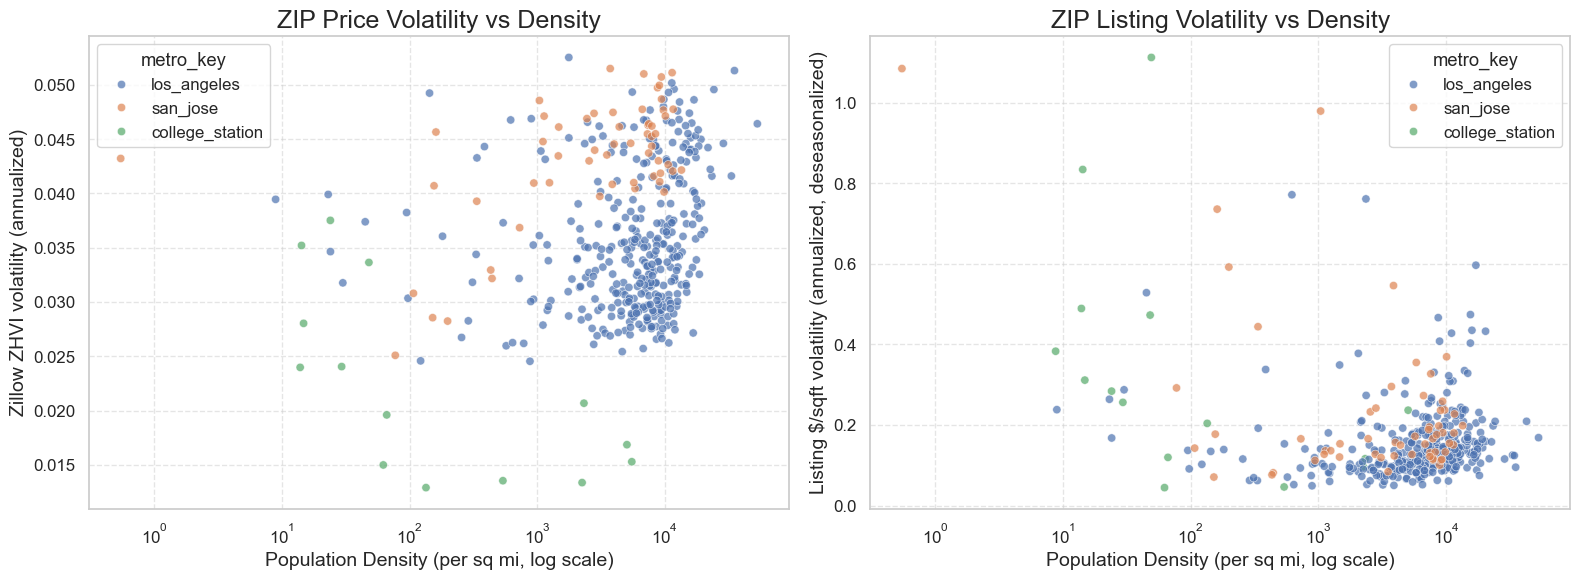

In [38]:
# Volatility measures, per ZIP:
#  - vol_zhvi: annualized std. dev. of monthly log changes in Zillow single-family ZHVI, 2012 onward.
#              ZHVI is smoothed and seasonally adjusted, so this understates true volatility but is
#              comparable across ZIPs and covers every ZIP.
#  - vol_listing: the same for Realtor.com list $/sqft (2016 onward), after removing each ZIP's
#              average change for each calendar month (seasonality). Noisy in thin markets, so the
#              regression weights each ZIP by its average number of active listings.
#  - drawdown_since_2022: worst fall from peak in ZHVI since Jan 2022 (a direct loan-risk measure).
#
# Regression: volatility = a + b * log10(density) [+ metro dummies] + error, robust (HC1) std. errors.
# b < 0 means denser ZIPs are less volatile. "Within metros" (with dummies) compares ZIPs in the
# same metro; "pooled" (no dummies) also uses the differences between metros.
from scipy import stats

WINDOW_START = '2012-01-01'
MIN_MONTHS_ZHVI, MIN_MONTHS_LISTING = 60, 48
listing_ppsf = 'rdc_median_listing_price_per_square_foot'
panel = panel.sort_values(['zip', 'month'])


def ann_vol(s, min_n):
    s = s.dropna()
    return s.std() * np.sqrt(12) if len(s) >= min_n else np.nan


# Zillow volatility + drawdown
z = panel.loc[panel['month'] >= WINDOW_START, ['zip', 'month', 'zhvi_sfr']].dropna()
z['dlog'] = z.groupby('zip')['zhvi_sfr'].transform(lambda s: np.log(s).diff())
vol_zhvi = z.groupby('zip')['dlog'].apply(lambda s: ann_vol(s, MIN_MONTHS_ZHVI)).rename('vol_zhvi')

def drawdown(s):
    s = s.dropna()
    return (s / s.cummax() - 1).min() if len(s) else np.nan
dd = (z[z['month'] >= '2022-01-01'].groupby('zip')['zhvi_sfr'].apply(drawdown)
      .rename('drawdown_since_2022'))

# Realtor.com volatility (deseasonalized) + listing weights
r = panel[['zip', 'month', listing_ppsf, 'rdc_active_listing_count']].dropna(subset=[listing_ppsf]).copy()
r['dlog'] = r.groupby('zip')[listing_ppsf].transform(lambda s: np.log(s).diff())
r['dlog_sa'] = r['dlog'] - r.groupby(['zip', r['month'].dt.month])['dlog'].transform('mean')
vol_listing = r.groupby('zip')['dlog_sa'].apply(lambda s: ann_vol(s, MIN_MONTHS_LISTING)).rename('vol_listing')
avg_listings = r.groupby('zip')['rdc_active_listing_count'].mean().rename('avg_listings')

vol = (census[['zip', 'metro_key', 'pop_density_per_sqmi']]
       .merge(pd.concat([vol_zhvi, vol_listing, dd, avg_listings], axis=1).reset_index(names='zip'),
              on='zip', how='left'))
vol = vol[vol['pop_density_per_sqmi'] > 0].copy()
vol['log10_density'] = np.log10(vol['pop_density_per_sqmi'])


def wls_hc1(y, X, w):
    """Weighted least squares with heteroskedasticity-robust (HC1) standard errors."""
    sw = np.sqrt(w)
    Xw, yw = X * sw[:, None], y * sw
    beta = np.linalg.lstsq(Xw, yw, rcond=None)[0]
    e = yw - Xw @ beta
    n, k = Xw.shape
    bread = np.linalg.inv(Xw.T @ Xw)
    meat = (Xw * e[:, None]).T @ (Xw * e[:, None])
    se = np.sqrt(np.diag(bread @ meat @ bread) * n / (n - k))
    return beta, se


def density_test(measure, weight=None, metro_dummies=True):
    d = vol.dropna(subset=[measure, 'log10_density'] + ([weight] if weight else []))
    X = [np.ones(len(d)), d['log10_density'].to_numpy()]
    if metro_dummies:
        X += [(d['metro_key'] == m).astype(float).to_numpy() for m in ['san_jose', 'college_station']]
    X = np.column_stack(X)
    w = d[weight].to_numpy() if weight else np.ones(len(d))
    beta, se = wls_hc1(d[measure].to_numpy(), X, w)
    t = beta[1] / se[1]
    return {'measure': measure, 'spec': 'within metros' if metro_dummies else 'pooled',
            'n_zips': len(d),
            'slope_per_10x_density': round(beta[1], 4), 'std_err': round(se[1], 4),
            'p_value': round(2 * stats.norm.sf(abs(t)), 4)}


tests = pd.DataFrame([
    density_test('vol_zhvi', metro_dummies=True),
    density_test('vol_zhvi', metro_dummies=False),
    density_test('vol_listing', weight='avg_listings', metro_dummies=True),
    density_test('vol_listing', weight='avg_listings', metro_dummies=False),
    density_test('drawdown_since_2022', metro_dummies=True),
])
print("Density vs. volatility (negative slope = denser ZIPs are less volatile):")
print(tests.to_string(index=False))
print("\nslope_per_10x_density: change in annualized volatility (0.01 = 1 percentage point) when")
print("density is 10x higher. For drawdown, a positive slope means denser ZIPs fell LESS.")

by_metro = vol.groupby('metro_key').agg(
    zips=('zip', 'count'),
    median_density=('pop_density_per_sqmi', 'median'),
    median_vol_zhvi=('vol_zhvi', 'median'),
    median_vol_listing=('vol_listing', 'median'),
    median_drawdown_since_2022=('drawdown_since_2022', 'median'),
).loc[metros].round(3)
print("\nBy metro:")
print(by_metro.to_string())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (measure, label) in zip(axes, [('vol_zhvi', 'Zillow ZHVI volatility (annualized)'),
                                       ('vol_listing', 'Listing $/sqft volatility (annualized, deseasonalized)')]):
    sns.scatterplot(data=vol, x='pop_density_per_sqmi', y=measure, hue='metro_key',
                    hue_order=metros, alpha=0.7, ax=ax)
    ax.set_xscale('log')
    ax.set_xlabel('Population Density (per sq mi, log scale)')
    ax.set_ylabel(label)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_title('ZIP Price Volatility vs Density')
axes[1].set_title('ZIP Listing Volatility vs Density')
plt.tight_layout()
plt.show()

In [ ]:
#Query to get the top LA zip codes with the lowest volatility rating to supliment with the final reccomendation. 

vol[vol.metro_key == 'los_angeles'].nsmallest(10, 'vol_zhvi')[['zip', 'vol_zhvi', 'pop_density_per_sqmi']]

,zip,vol_zhvi,pop_density_per_sqmi
233,91387,0.024549,877.351603
234,91390,0.024587,122.106701
226,91354,0.025433,4634.502525
348,92833,0.025719,6760.824204
231,91381,0.025975,571.161191
223,91350,0.026104,2771.524014
345,92823,0.026194,784.066524
117,90401,0.026242,10729.801325
372,93551,0.026262,641.370522
134,90621,0.026586,8583.969466
